In [1]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

data = np.array([[10000], [25000], [50000], [75000], [100000]])

scaler = MinMaxScaler()
normalized_data = scaler.fit_transform(data)

print(normalized_data)

[[0.        ]
 [0.16666667]
 [0.44444444]
 [0.72222222]
 [1.        ]]


In [2]:
import numpy as np
from sklearn.preprocessing import StandardScaler
data = np.array([[10000], [25000], [50000], [75000], [100000]])
scaler = StandardScaler()
standerized_data = scaler.fit_transform(data)
print(standerized_data)

[[-1.28638417]
 [-0.82696125]
 [-0.06125639]
 [ 0.70444848]
 [ 1.47015334]]


In [3]:
data = [2, 4, 6, 8, 2, 4, 6]
from sklearn.preprocessing import LabelEncoder
Le = LabelEncoder()
encoded_data = Le.fit_transform(data)
print(encoded_data)

[0 1 2 3 0 1 2]


In [4]:
from sklearn.preprocessing import OneHotEncoder
import numpy as np
data = [['Red'], ['Blue'], ['Green']]
print(data)
ohe = OneHotEncoder()
encoded_data = ohe.fit_transform(data)
print(encoded_data)

[['Red'], ['Blue'], ['Green']]
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 3 stored elements and shape (3, 3)>
  Coords	Values
  (0, 2)	1.0
  (1, 0)	1.0
  (2, 1)	1.0


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [6]:
data =  {
    'Hours': [
        1, 2, 3, 4, 5,
        6, 7, 8, 9, 10,
        11, 12, 13, 14, 15,
        16, 17, 18, 19, 20
    ],

    'Score':[
        35, 40, 45, 50, 55,
        60, 62, 65, 68, 70,
        72, 75, 78, 80, 82,
        85, 87, 90, 92, 95
    ]
}
df = pd.DataFrame(data)
print(df)

    Hours  Score
0       1     35
1       2     40
2       3     45
3       4     50
4       5     55
5       6     60
6       7     62
7       8     65
8       9     68
9      10     70
10     11     72
11     12     75
12     13     78
13     14     80
14     15     82
15     16     85
16     17     87
17     18     90
18     19     92
19     20     95


In [7]:
print("\n\nDataset Information")

print("Number of observations:", len(df))
print("Number of variables:", len(df.columns))

print("\nStatistical Summary")
print(df.describe())



Dataset Information
Number of observations: 20
Number of variables: 2

Statistical Summary
          Hours      Score
count  20.00000  20.000000
mean   10.50000  69.300000
std     5.91608  17.648915
min     1.00000  35.000000
25%     5.75000  58.750000
50%    10.50000  71.000000
75%    15.25000  82.750000
max    20.00000  95.000000


In [8]:
#Independent variable (X)
X = df[['Hours']]

#Dependent variable (Y)
Y = df[['Score']]

print("Independent Variable (X): Hours Studied")
print(X)
print("Dependent Variable (Y): Exam Score")
print(Y)


Independent Variable (X): Hours Studied
    Hours
0       1
1       2
2       3
3       4
4       5
5       6
6       7
7       8
8       9
9      10
10     11
11     12
12     13
13     14
14     15
15     16
16     17
17     18
18     19
19     20
Dependent Variable (Y): Exam Score
    Score
0      35
1      40
2      45
3      50
4      55
5      60
6      62
7      65
8      68
9      70
10     72
11     75
12     78
13     80
14     82
15     85
16     87
17     90
18     92
19     95


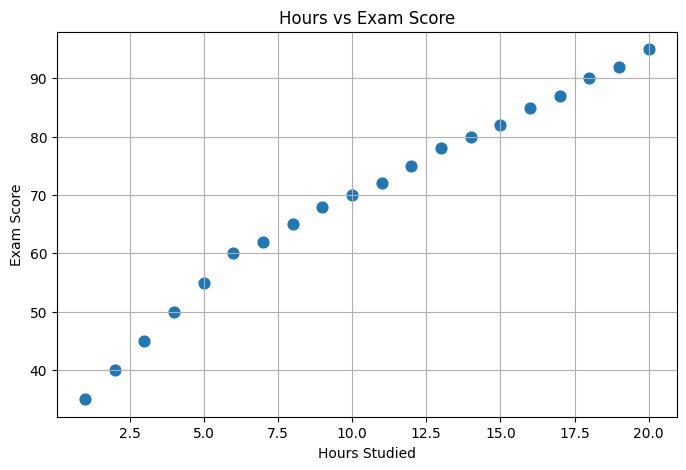

In [9]:
plt.figure(figsize=(8,5))
plt.scatter(X, Y, s=60)
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.title('Hours vs Exam Score')
plt.grid(True)
plt.show()

In [10]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.20, random_state=42)
print("Training Samples:", len(x_train))
print("Testing Samples:", len(x_test))

Training Samples: 16
Testing Samples: 4


In [11]:
#Scaling is particularly useful for Ridge and Lasso
#Tree-based models do not require scaling

scaler = StandardScaler()
X_train_Scaler = scaler.fit_transform(x_train)
X_test_Scaler = scaler.transform(x_test)

In [12]:
# 1. SIMPLE LINEAR REGRESSION
linear_model = LinearRegression()
linear_model.fit(x_train, y_train)
linear_pred = linear_model.predict(x_test)
print("Intercept:", linear_model.intercept_[0])
print("Slope:", linear_model.coef_[0][0])
print("Regression Equation:")
print("Score =", round(linear_model.intercept_[0], 2), "+", round(linear_model.coef_[0][0], 2), "x Hours")

Intercept: 41.36223797315638
Slope: 2.741064696124265
Regression Equation:
Score = 41.36 + 2.74 x Hours


In [13]:
# 2. Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(x_train, y_train)
ridge_pred = ridge_model.predict(X_test_Scaler)

print("\nRIDGE REGRESSION")
print("=" * 50)
print("Alpha:", ridge_model.alpha)
print("Coefficient:", round(ridge_model.coef_[0], 2))
print("Intercept:", round(ridge_model.intercept_[0], 2))



RIDGE REGRESSION
Alpha: 1.0
Coefficient: 2.73
Intercept: 41.43


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(


In [14]:
# 3. LASSO REGRESSION
lasso_model = Lasso(alpha=1.0)
lasso_model.fit(x_train, y_train)
lasso_pred = lasso_model.predict(X_test_Scaler)

print("\nLASSO REGRESSION")
print("=" * 50)
print("Alpha:", lasso_model.alpha)
print("Coefficient:", round(lasso_model.coef_[0], 2))
print("Intercept:", round(lasso_model.intercept_[0], 2))


LASSO REGRESSION
Alpha: 1.0
Coefficient: 2.7
Intercept: 41.78


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Lasso was fitted with feature names
  warnings.warn(


In [15]:
#4. Decision Tree Regression
tree_model = DecisionTreeRegressor(max_depth = 3, random_state = 42)
tree_model.fit(x_train, y_train)
tree_pred = tree_model.predict(x_test)
print("\nDECISION TREE REGRESSION")
print("=" * 50)
print("Maximum Depth:", tree_model.max_depth)


DECISION TREE REGRESSION
Maximum Depth: 3


In [16]:
#5. Random Forest Regression
forest_model = RandomForestRegressor(n_estimators = 100, max_depth =3, random_state = 42)
forest_model.fit(x_train, y_train)
forest_pred = forest_model.predict(x_test)
print("n\Random Forest Regression")
print("=" * 50)
print("Number of Estimators:", forest_model.n_estimators)
print("Maximum Depth:", forest_model.max_depth)

<>:5: SyntaxWarning: invalid escape sequence '\R'
<>:5: SyntaxWarning: invalid escape sequence '\R'
/tmp/ipykernel_966/2722098544.py:5: SyntaxWarning: invalid escape sequence '\R'
  print("n\Random Forest Regression")
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


n\Random Forest Regression
Number of Estimators: 100
Maximum Depth: 3


In [17]:
prediction = {
    'Linear Regression': linear_pred,
    'Ridge Regression': ridge_pred,
    'Lasso Regression': lasso_pred,
    'Decision Tree Regression': tree_pred,
    'Random Forest Regression': forest_pred
}

In [18]:
results = []


for model_name, prediction in prediction.items():
  mae = mean_absolute_error(y_test, prediction)
  mse = mean_squared_error(y_test, prediction)
  rmse = np.sqrt(mse)
  r2 = r2_score(y_test, prediction)
  results.append([model_name, mae, mse, rmse, r2])

results_df = pd.DataFrame(results, columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2 Score'])
print(results_df)

                      Model        MAE         MSE       RMSE  R2 Score
0         Linear Regression   4.217086   32.563883   5.706477  0.948414
1          Ridge Regression  22.486670  918.426447  30.305551 -0.454933
2          Lasso Regression  22.334654  905.012569  30.083427 -0.433683
3  Decision Tree Regression   5.750000   39.750000   6.304760  0.937030
4  Random Forest Regression   6.047792   57.755967   7.599735  0.908505


In [19]:
print(results_df.round(4).to_string(index=False))

                   Model     MAE      MSE    RMSE  R2 Score
       Linear Regression  4.2171  32.5639  5.7065    0.9484
        Ridge Regression 22.4867 918.4264 30.3056   -0.4549
        Lasso Regression 22.3347 905.0126 30.0834   -0.4337
Decision Tree Regression  5.7500  39.7500  6.3048    0.9370
Random Forest Regression  6.0478  57.7560  7.5997    0.9085


In [20]:
comparison = pd.DataFrame({
    'Hours': x_test['Hours'].values,
    'Actual Score': y_test.values.ravel(),
    'Linear Regression': linear_pred.ravel(),
    'Ridge Regression': ridge_pred.ravel(),
    'Lasso Regression': lasso_pred.ravel(),
    'Decision Tree Regression': tree_pred.ravel(),
    'Random Forest Regression': forest_pred.ravel()
})

comparison = comparison.sort_values(by='Hours')

print("\nActual vs Predicted Values")
print(comparison.round(2).to_string(index=False))



Actual vs Predicted Values
 Hours  Actual Score  Linear Regression  Ridge Regression  Lasso Regression  Decision Tree Regression  Random Forest Regression
     1            35              44.10             36.16             36.57                      45.0                     47.77
     2            40              46.84             36.70             37.10                      45.0                     47.77
    16            85              85.22             44.22             44.53                      80.0                     82.56
    18            90              90.70             45.30             45.60                      87.0                     88.80


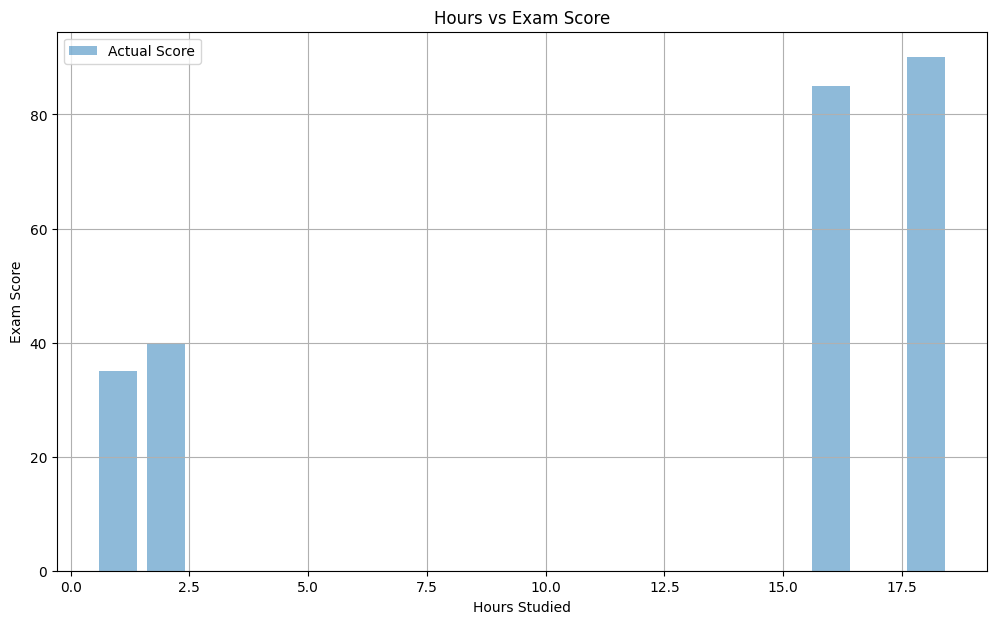

In [21]:
#bar plot
plt.figure(figsize=(12, 7))
plt.bar(comparison['Hours'], comparison['Actual Score'], label='Actual Score', alpha=0.5)
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.title('Hours vs Exam Score')
plt.legend()
plt.grid(True)
plt.show()

In [22]:
X_range = np.linspace(X['Hours'].min(),X['Hours'].max(), 200).reshape(-1,1)
X_range

array([[ 1.        ],
       [ 1.09547739],
       [ 1.19095477],
       [ 1.28643216],
       [ 1.38190955],
       [ 1.47738693],
       [ 1.57286432],
       [ 1.66834171],
       [ 1.7638191 ],
       [ 1.85929648],
       [ 1.95477387],
       [ 2.05025126],
       [ 2.14572864],
       [ 2.24120603],
       [ 2.33668342],
       [ 2.4321608 ],
       [ 2.52763819],
       [ 2.62311558],
       [ 2.71859296],
       [ 2.81407035],
       [ 2.90954774],
       [ 3.00502513],
       [ 3.10050251],
       [ 3.1959799 ],
       [ 3.29145729],
       [ 3.38693467],
       [ 3.48241206],
       [ 3.57788945],
       [ 3.67336683],
       [ 3.76884422],
       [ 3.86432161],
       [ 3.95979899],
       [ 4.05527638],
       [ 4.15075377],
       [ 4.24623116],
       [ 4.34170854],
       [ 4.43718593],
       [ 4.53266332],
       [ 4.6281407 ],
       [ 4.72361809],
       [ 4.81909548],
       [ 4.91457286],
       [ 5.01005025],
       [ 5.10552764],
       [ 5.20100503],
       [ 5

In [23]:
#Prediction for smooth curves
linear_curve = linear_model.predict(X_range)
ridge_curve = ridge_model.predict(scaler.transform(X_range))
lasso_curve = lasso_model.predict(scaler.transform(X_range))
tree_curve = tree_model.predict(X_range)
forest_curve = forest_model.predict(X_range)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Lasso was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.p

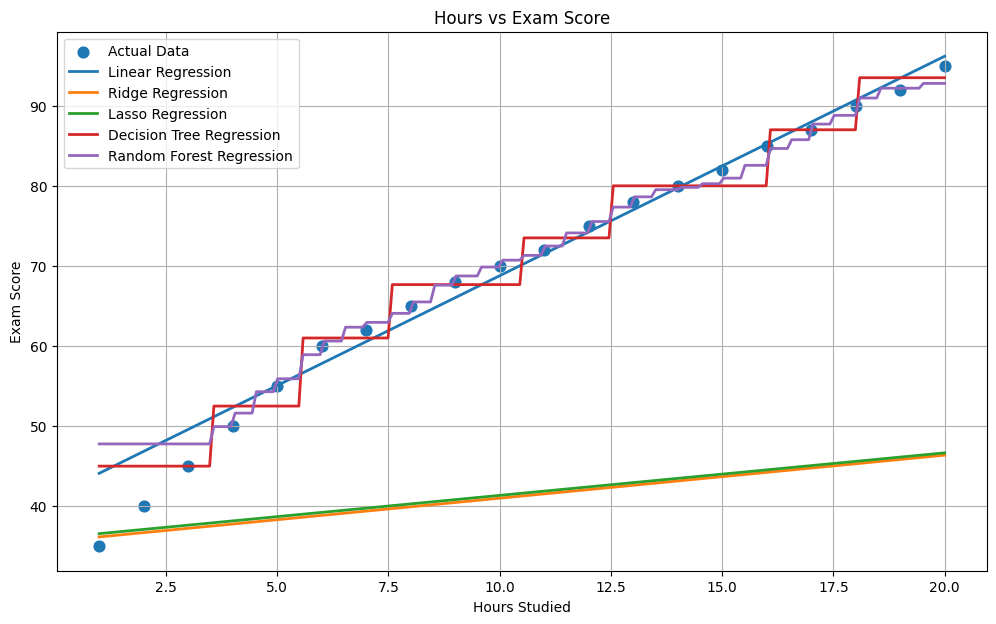

In [24]:
#PLOT ALL REGRESIION MODELS
plt.figure(figsize=(12, 7))
#actual data
plt.scatter(X, Y, s=60, label='Actual Data')
#Linear Regression
plt.plot(X_range, linear_curve, linewidth=2, label='Linear Regression')
#Ridge Regression
plt.plot(X_range, ridge_curve, linewidth=2, label='Ridge Regression')
#Lasso Regression
plt.plot(X_range, lasso_curve, linewidth=2, label='Lasso Regression')
#Decision Tree Regression
plt.plot(X_range, tree_curve, linewidth=2, label='Decision Tree Regression')
#Random Forest Regression
plt.plot(X_range, forest_curve, linewidth=2, label='Random Forest Regression')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.title('Hours vs Exam Score')
plt.legend()
plt.grid(True)
plt.show()

In [25]:
new_hours = [[12]]
new_linear = linear_model.predict(new_hours)[0]
new_ridge = ridge_model.predict(scaler.transform(new_hours))[0]
new_lasso = lasso_model.predict(scaler.transform(new_hours))[0]
new_tree = tree_model.predict(new_hours)[0]
new_forest = forest_model.predict(new_hours)[0]
prediction_result = pd.DataFrame({
    'Model' : ['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'Decision Tree Regression', 'Random Forest Regression'],
    'Predicted Score': [new_linear, new_ridge, new_lasso, new_tree, new_forest]
})
print("prediction for New Student")
print("Hours Studied:", new_hours[0][0])
print(prediction_result.round(2).to_string(index=False))

prediction for New Student
Hours Studied: 12
                   Model     Predicted Score
       Linear Regression [74.25501432664757]
        Ridge Regression           42.071603
        Lasso Regression           42.410226
Decision Tree Regression                73.5
Random Forest Regression             74.1195


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Lasso was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.p

In [26]:
models = {
    'Linear Regression': linear_model,
    'Ridge Regression': ridge_model,
    'Lasso Regression': lasso_model,
    'Decision Tree Regression': tree_model,
    'Random Forest Regression': forest_model
}

In [27]:
best_model_name = results_df.loc[results_df['R2 Score'].idxmax(), 'Model']
best_model = models[best_model_name]

In [28]:
best_model

LinearRegression()

In [29]:
import joblib
joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [30]:
model = joblib.load('best_model.pkl')
scaler = joblib.load('scaler.pkl')

In [31]:
def predict_score(hours):
    sample_hours = np.array([hours])
    #sample_hours= scaler.transform(sample_hours)
    prediction = model.predict([sample_hours])
    return f"Predicted Score Based on Hours: {int(prediction[0])}"

In [32]:
import gradio as gr

interface = gr.Interface(
    fn=predict_score,
    inputs=[gr.Number(label="Enter Hours")],
    outputs="text",
    title="Score Prediction System based on Hours",
    description="Enter Hours"
)
interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4890874a1ccd38ce3d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
